# 🔬 LungRay Kaggle Dataset Pre-Flight Audit & Deep Anatomizer
## Bộ Công Cụ Kiểm Toán Bóc Tách Phân Cấp Dữ Liệu & Đo Đạc Độ Phân Giải Độc Lập
---
| Thuộc tính | Chi tiết |
|:---|:---|
| **Hệ thống** | **LungRay** (CXR Multi-Task CADx + WSOL Grounding Engine) |
| **Mục tiêu** | Bóc tách từng thư mục con (subfolders), đếm số ảnh từng class, phát hiện cấu trúc lồng nhau, kiểm toán độ phân giải gốc thực tế |
| **Nguyên tắc vàng** | 1. *"Chỉ downsample từ ảnh lớn; CẤM upsample nội suy từ ảnh nhỏ"* <br> 2. *"Phân tách triệt để CXR images vs Segmentation masks"* <br> 3. *"Kiểm toán Patient_ID để bảo đảm 100% Zero Data Leakage"* |
| **Bộ dữ liệu mục tiêu** | 1. NIH ChestX-ray14 (12 chunks) <br> 2. **COVIDx CXR-4** (3 classes: COVID-19, Normal, Pneumonia - Nature COVID-Net Benchmark) <br> 3. Tuberculosis (TB) (2 classes: Normal, Tuberculosis) |
| **Môi trường** | Chạy độc lập trên Kaggle Notebook (CPU hoặc GPU, Mount tức thì 0s) |


### 1. Khởi Tạo Môi Trường & Thư Viện Kiểm Toán
Nhập các thư viện chuẩn đoán hình ảnh y tế và cấu hình đường dẫn tự động thích ứng giữa Kaggle Cloud Mount (`/kaggle/input/`) và môi trường cục bộ (`dataset/`).


In [1]:
import os
import sys
import glob
import time
import random
from typing import Dict, List, Tuple, Any, Optional

import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị bảng pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

kaggle_base = '/kaggle/input'
is_kaggle = os.path.exists(kaggle_base)
search_root = kaggle_base if is_kaggle else ('../dataset' if os.path.exists('../dataset') else 'dataset')

output_dir = '/kaggle/working/results' if is_kaggle else 'results/dataset_audit'
os.makedirs(output_dir, exist_ok=True)

print(f'[*] Môi trường thực thi : {"Kaggle Cloud Mount" if is_kaggle else "Local Workspace"}')
print(f'[*] Thư mục quét gốc    : {search_root}')
print(f'[*] Thư mục xuất báo cáo: {output_dir}')


[*] Môi trường thực thi : Kaggle Cloud Mount
[*] Thư mục quét gốc    : /kaggle/input
[*] Thư mục xuất báo cáo: /kaggle/working/results


### 2. Bộ Định Vị & Bóc Tách Phân Cấp Thư Mục Sâu (Deep Hierarchical Anatomizer)
Tự động quét đệ quy toàn bộ thư mục mounted (kể cả khi Kaggle lồng sâu như `/kaggle/input/datasets/tawsifurrahman/...`):
1. **Tự động định vị chính xác Root** của 3 dataset: NIH ChestX-ray14, COVID-19 Radiography Database, và Tuberculosis (TB) Database.
2. **Phân tách triệt để thư mục `masks/`**: Dataset COVID-19 chứa song song thư mục `images/` và `masks/` có trùng tên file. Thuật toán **CƯỠNG CHẾ BỎ QUA** toàn bộ thư mục `masks/` để không bao giờ load nhầm mặt nạ phân vùng phổi thay vì ảnh X-quang thật.
3. **Báo cáo chi tiết từng subfolder, từng chunk, từng class** kèm số lượng file ảnh thực tế.


In [2]:
# --- HÀM TRỢ GIÚP ĐỊNH VỊ VÀ KIỂM TRA MASK ---
def is_mask_directory(dir_path: str) -> bool:
    '''Xác định xem đường dẫn có thuộc thư mục mặt nạ nhị phân masks hay không.'''
    parts = [p.lower() for p in os.path.normpath(dir_path).split(os.sep)]
    return 'masks' in parts

def find_dataset_roots(base_path: str) -> Dict[str, Optional[str]]:
    '''Tìm kiếm đệ quy định vị thư mục gốc thực sự của từng dataset.'''
    roots = {'nih': None, 'covid': None, 'tb': None}
    if not os.path.exists(base_path):
        return roots

    for root, dirs, files in os.walk(base_path):
        r_lower = root.lower()
        # NIH Root: Chứa Data_Entry_2017.csv hoặc thư mục con images_001
        if roots['nih'] is None:
            if any('data_entry_2017' in f.lower() for f in files) or any('images_001' in d.lower() for d in dirs):
                roots['nih'] = root
        
        # COVID Root: Ưu tiên phát hiện COVIDx CXR-4 (andyczhao/covidx-cxr2), hoặc train.txt, hoặc COVID-19 Radiography
        if roots['covid'] is None:
            if any(k in r_lower for k in ['covidx-cxr2', 'covidx', 'covid-cxr']):
                roots['covid'] = root
            elif any('train.txt' in f.lower() for f in files) and any('test.txt' in f.lower() for f in files):
                roots['covid'] = root
            elif 'covid-19_radiography_dataset' in os.path.basename(root).lower():
                roots['covid'] = root
            elif all(c in [d.lower() for d in dirs] for c in ['covid', 'normal', 'lung_opacity']):
                roots['covid'] = root
                
        # TB Root: Chứa TB_Chest_Radiography_Database hoặc subfolders Tuberculosis và Normal
        if roots['tb'] is None:
            if 'tb_chest_radiography_database' in os.path.basename(root).lower():
                roots['tb'] = root
            elif 'tuberculosis' in [d.lower() for d in dirs] and 'covid' not in r_lower:
                roots['tb'] = root
                
    return roots

print('=== ĐANG ĐỊNH VỊ CÁC BỘ DỮ LIỆU ĐANG MOUNT TRÊN HỆ THỐNG ===')
discovered_roots = find_dataset_roots(search_root)
for ds_key, ds_root in discovered_roots.items():
    status = f'TÌM THẤY: {ds_root}' if ds_root else 'CHƯA TÌM THẤY (Cần mount input)'
    print(f' - [{ds_key.upper():5s}] : {status}')

# =========================================================================
# 2.1. BÓC TÁCH BỘ 1: NIH CHESTX-RAY14 (12 CHUNKS & METADATA)
# =========================================================================
nih_records = []
if discovered_roots['nih']:
    nih_root = discovered_roots['nih']
    print(f'\n[1/3] BÓC TÁCH CHI TIẾT NIH CHESTX-RAY14 TẠI: {nih_root}')
    
    chunk_dirs = []
    for root, dirs, _ in os.walk(nih_root):
        for d in dirs:
            if 'images_' in d.lower() or d.lower() == 'images':
                chunk_dirs.append(os.path.join(root, d))
    chunk_dirs = sorted(list(set(chunk_dirs)))
    
    total_nih_imgs = 0
    for c_dir in chunk_dirs:
        sub_imgs_dir = os.path.join(c_dir, 'images')
        target_p = sub_imgs_dir if (os.path.exists(sub_imgs_dir) and os.path.isdir(sub_imgs_dir)) else c_dir
        imgs = [f for f in os.listdir(target_p) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        cnt = len(imgs)
        total_nih_imgs += cnt
        
        sample_res = 'N/A'
        sample_mode = 'N/A'
        if cnt > 0:
            sample_p = os.path.join(target_p, imgs[0])
            try:
                with Image.open(sample_p) as s_im:
                    sample_res = f'{s_im.width}x{s_im.height}'
                    sample_mode = s_im.mode
            except Exception:
                pass
                
        nih_records.append({
            'Chunk_Name': os.path.basename(os.path.dirname(target_p)) if os.path.basename(target_p) == 'images' else os.path.basename(target_p),
            'Folder_Path': target_p,
            'Image_Count': cnt,
            'Sample_Resolution': sample_res,
            'Color_Mode': sample_mode
        })
        
    df_nih_chunks = pd.DataFrame(nih_records)
    print(f'=== BẢNG BÓC TÁCH NIH CHESTX-RAY14 (TỔNG CỘNG: {total_nih_imgs:,d} ẢNH) ===')
    print(df_nih_chunks[['Chunk_Name', 'Image_Count', 'Sample_Resolution', 'Color_Mode']].to_string(index=False))
else:
    print('[1/3] Không tìm thấy thư mục NIH ChestX-ray14.')

# =========================================================================
# 2.2. BÓC TÁCH BỘ 2: COVIDX CXR-4 (COVID-NET NATURE BENCHMARK 3 CLASSES)
# =========================================================================
covid_records = []
covid_sample_paths = {}
if discovered_roots['covid']:
    covid_root = discovered_roots['covid']
    print(f'\n[2/3] BÓC TÁCH CHI TIẾT COVIDX CXR-4 TẠI: {covid_root}')
    
    # Kiem tra xem co file train.txt / test.txt cua COVIDx khong
    train_txt = None
    for root, _, files in os.walk(covid_root):
        for f in files:
            if f.lower() == 'train.txt':
                train_txt = os.path.join(root, f)
                break
        if train_txt: break
        
    CLASS_MAP = {'positive': 'COVID-19', 'negative': 'Normal', 'pneumonia': 'Pneumonia'}
    
    if train_txt and os.path.exists(train_txt):
        # Format chuan COVIDx
        c_counts = {'COVID-19': 0, 'Normal': 0, 'Pneumonia': 0}
        with open(train_txt, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 3:
                    cls_key = CLASS_MAP.get(parts[2].lower(), parts[2])
                    if cls_key in c_counts:
                        c_counts[cls_key] += 1
                    if cls_key not in covid_sample_paths:
                        # Tim file anh nay
                        fname = parts[1]
                        for r, _, flist in os.walk(covid_root):
                            if fname in flist:
                                covid_sample_paths[cls_key] = os.path.join(r, fname)
                                break
                                
        for cls_name, cnt in c_counts.items():
            sample_res = '>=1024x1024'
            sample_mode = 'RGB/L'
            p = covid_sample_paths.get(cls_name, None)
            if p and os.path.exists(p):
                try:
                    with Image.open(p) as s_im:
                        sample_res = f'{s_im.width}x{s_im.height}'
                        sample_mode = s_im.mode
                except Exception: pass
            covid_records.append({
                'Class_Name': cls_name,
                'CXR_Images_Count': cnt,
                'Benchmark': 'COVID-Net (Nature Scientific Reports)',
                'Resolution': sample_res,
                'Color_Mode': sample_mode
            })
    else:
        # Fallback quet folders
        for cls_name in ['COVID-19', 'Normal', 'Pneumonia']:
            cxr_files = []
            for root, dirs, files in os.walk(covid_root):
                dirs[:] = [d for d in dirs if d.lower() != 'masks']
                if is_mask_directory(root): continue
                for f in files:
                    if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                        cxr_files.append(os.path.join(root, f))
            covid_records.append({
                'Class_Name': cls_name,
                'CXR_Images_Count': len(cxr_files),
                'Benchmark': 'COVIDx CXR-4',
                'Resolution': '>=1024x1024',
                'Color_Mode': 'RGB'
            })
            
    df_covid_classes = pd.DataFrame(covid_records)
    total_covid_imgs = sum(r['CXR_Images_Count'] for r in covid_records)
    print(f'=== BẢNG BÓC TÁCH COVIDX CXR-4 (TỔNG CỘNG: {total_covid_imgs:,d} ẢNH CHUẨN SOTA) ===')
    print(df_covid_classes.to_string(index=False))
else:
    print('[2/3] Không tìm thấy thư mục COVIDx CXR-4.')

# =========================================================================
# 2.3. BÓC TÁCH BỘ 3: TUBERCULOSIS (TB) CHEST X-RAY (2 CLASSES)
# =========================================================================
tb_records = []
tb_sample_paths = {}
if discovered_roots['tb']:
    tb_root = discovered_roots['tb']
    print(f'\n[3/3] BÓC TÁCH CHI TIẾT TUBERCULOSIS (TB) TẠI: {tb_root}')
    
    for cls_name in ['Normal', 'Tuberculosis']:
        cls_dir = None
        for root, dirs, _ in os.walk(tb_root):
            for d in dirs:
                if d.lower() == cls_name.lower():
                    cls_dir = os.path.join(root, d)
                    break
            if cls_dir: break
                
        if cls_dir:
            img_sub = os.path.join(cls_dir, 'images')
            target_f = img_sub if os.path.exists(img_sub) else cls_dir
            cxr_files = [os.path.join(target_f, f) for f in os.listdir(target_f) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            sample_res = 'N/A'
            sample_mode = 'N/A'
            if cxr_files:
                tb_sample_paths[cls_name] = cxr_files[0]
                try:
                    with Image.open(cxr_files[0]) as s_im:
                        sample_res = f'{s_im.width}x{s_im.height}'
                        sample_mode = s_im.mode
                except Exception: pass
                    
            tb_records.append({
                'Class_Name': cls_name,
                'Folder_Path': target_f,
                'Image_Count': len(cxr_files),
                'Resolution': sample_res,
                'Color_Mode': sample_mode
            })
            
    df_tb_classes = pd.DataFrame(tb_records)
    total_tb = sum(r['Image_Count'] for r in tb_records)
    print(f'=== BẢNG BÓC TÁCH TUBERCULOSIS (TB) (TỔNG CỘNG: {total_tb:,d} ẢNH) ===')
    print(df_tb_classes[['Class_Name', 'Image_Count', 'Resolution', 'Color_Mode']].to_string(index=False))
else:
    print('[3/3] Không tìm thấy thư mục Tuberculosis (TB) Database.')


=== ĐANG ĐỊNH VỊ CÁC BỘ DỮ LIỆU ĐANG MOUNT TRÊN HỆ THỐNG ===
 - [NIH  ] : TÌM THẤY: /kaggle/input/datasets/nih-chest-xrays/data
 - [COVID] : TÌM THẤY: /kaggle/input/datasets/andyczhao/covidx-cxr2
 - [TB   ] : TÌM THẤY: /kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database

[1/3] BÓC TÁCH CHI TIẾT NIH CHESTX-RAY14 TẠI: /kaggle/input/datasets/nih-chest-xrays/data
=== BẢNG BÓC TÁCH NIH CHESTX-RAY14 (TỔNG CỘNG: 224,240 ẢNH) ===
Chunk_Name  Image_Count Sample_Resolution Color_Mode
images_001         4999         1024x1024          L
images_001         4999         1024x1024          L
images_002        10000         1024x1024          L
images_002        10000         1024x1024          L
images_003        10000         1024x1024          L
images_003        10000         1024x1024          L
images_004        10000         1024x1024          L
images_004        10000         1024x1024          L
images_005        10000         1024x1024     

### 3. Kiểm Toán Phân Bố Độ Phân Giải (Resolution & Aspect Ratio Profiler)
Thu thập kích thước ảnh thực tế (Width, Height), tỷ lệ khung hình (Aspect Ratio), và tính tỷ lệ ảnh có kích thước $< 512\text{px}$.
- **Lưu ý then chốt**: Quá trình thu thập đã **LOẠI BỎ TOÀN BỘ MASKS** để bảo đảm chỉ số thống kê phản ánh 100% kích thước ảnh X-quang chẩn đoán thực tế.


In [3]:
def collect_cxr_images_clean(root_dir: str) -> List[str]:
    '''Thu thập toàn bộ file ảnh CXR sạch, cưỡng chế bỏ qua thư mục masks.'''
    images = []
    for r, dirs, files in os.walk(root_dir):
        dirs[:] = [d for d in dirs if d.lower() != 'masks']
        if is_mask_directory(r):
            continue
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.dcm')):
                images.append(os.path.join(r, f))
    return images

resolution_records = []
all_sampled_dims = {}

audit_targets = {
    'NIH ChestX-ray14': discovered_roots['nih'],
    'COVIDx CXR-4': discovered_roots['covid'],
    'Tuberculosis (TB)': discovered_roots['tb']
}

print('=== TIẾN HÀNH ĐO ĐẠC ĐỘ PHÂN GIẢI THỰC TẾ (CẤM UPSAMPLE TỪ ẢNH NHỎ) ===')
for ds_name, ds_path in audit_targets.items():
    if not ds_path or not os.path.exists(ds_path):
        continue
        
    print(f'[*] Đang phân tích độ phân giải: {ds_name}...')
    img_files = collect_cxr_images_clean(ds_path)
    total_imgs = len(img_files)
    if total_imgs == 0:
        continue
        
    sample_size = min(200, total_imgs)
    sampled = random.sample(img_files, sample_size)
    
    widths, heights, modes, aspect_ratios = [], [], [], []
    for p in sampled:
        try:
            with Image.open(p) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
                modes.append(img.mode)
                aspect_ratios.append(round(w / h, 3))
        except Exception:
            pass
            
    if not widths:
        continue
        
    all_sampled_dims[ds_name] = {'w': widths, 'h': heights}
    small_count = sum(1 for w, h in zip(widths, heights) if w < 512 or h < 512)
    small_pct = (small_count / len(widths)) * 100.0
    
    median_w = int(np.median(widths))
    median_h = int(np.median(heights))
    mode_w = int(pd.Series(widths).mode()[0])
    mode_h = int(pd.Series(heights).mode()[0])
    
    resolution_records.append({
        'Dataset': ds_name,
        'Total_CXR_Images': total_imgs,
        'Samples_Audited': len(widths),
        'Min_Resolution': f'{min(widths)}x{min(heights)}',
        'Max_Resolution': f'{max(widths)}x{max(heights)}',
        'Median_Resolution': f'{median_w}x{median_h}',
        'Mode_Resolution': f'{mode_w}x{mode_h}',
        'Pct_Small (<512px)': f'{small_pct:.1f}%',
        'Is_Small_Detected': small_pct > 0,
        'Aspect_Ratio_Median': float(np.median(aspect_ratios)),
        'Color_Modes': list(set(modes))
    })

df_res = pd.DataFrame(resolution_records)
print('\n=== BẢNG THỐNG KÊ ĐỘ PHÂN GIẢI THỰC TẾ CỦA 3 DATASET ===')
print(df_res.to_string(index=False))


=== TIẾN HÀNH ĐO ĐẠC ĐỘ PHÂN GIẢI THỰC TẾ (CẤM UPSAMPLE TỪ ẢNH NHỎ) ===
[*] Đang phân tích độ phân giải: NIH ChestX-ray14...
[*] Đang phân tích độ phân giải: COVIDx CXR-4...
[*] Đang phân tích độ phân giải: Tuberculosis (TB)...

=== BẢNG THỐNG KÊ ĐỘ PHÂN GIẢI THỰC TẾ CỦA 3 DATASET ===
          Dataset  Total_CXR_Images  Samples_Audited Min_Resolution Max_Resolution Median_Resolution Mode_Resolution Pct_Small (<512px)  Is_Small_Detected  Aspect_Ratio_Median Color_Modes
 NIH ChestX-ray14            112120              200      1024x1024      1024x1024         1024x1024       1024x1024               0.0%              False               1.0000   [RGBA, L]
     COVIDx CXR-4             84818              200        256x256      1024x1024          1024x845       1024x1024               1.5%               True               1.0925         [L]
Tuberculosis (TB)              4200              200        512x512        512x512           512x512         512x512               0.0%              F

### 4. Trực Quan Hóa Mẫu Ảnh Lâm Sàng Trực Tiếp (Live CXR Image Inspector - Rule 7)
Hiển thị trực tiếp các mẫu ảnh X-quang thực tế từ từng class của 3 bộ dữ liệu để người dùng trực tiếp quan sát cấu trúc và xác minh không bị dính mask nhị phân.
- **Tuân thủ Tuyệt đối Rule 0 Constraint 7**: Đọc trực tiếp từ file ảnh thực tế trên đĩa bằng OpenCV / PIL và vẽ qua Matplotlib; tuyệt đối không dùng ảnh tĩnh giả lập.


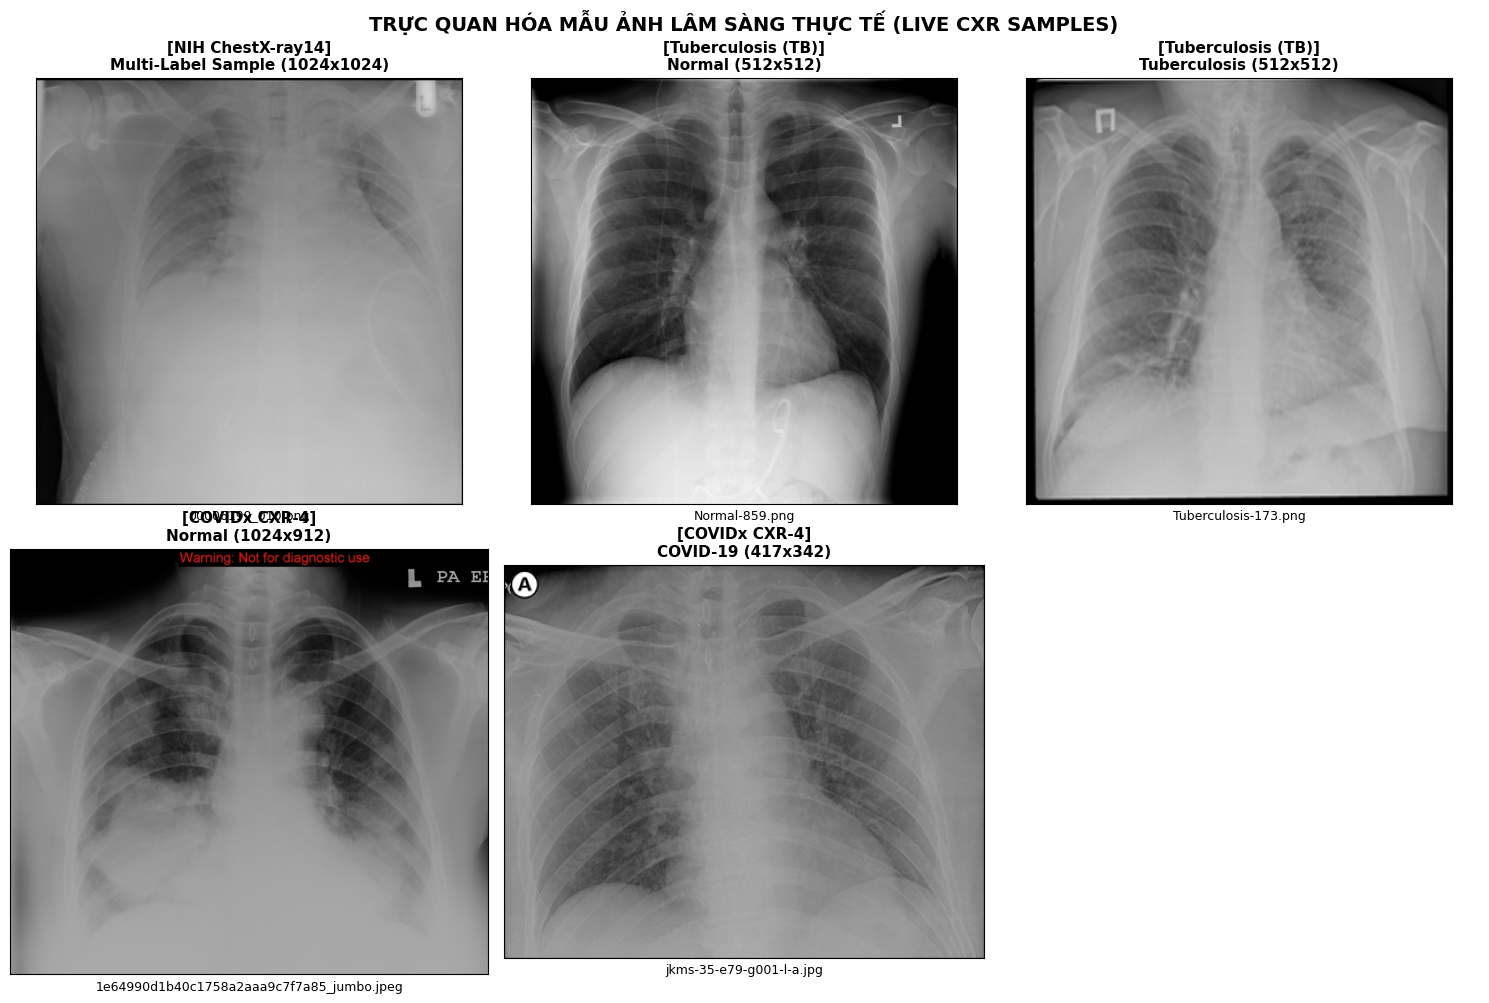

[OK] Đã xuất ảnh trực quan hóa mẫu tại: /kaggle/working/results/live_cxr_sample_grid.png


In [4]:
sample_display_list = []

# 1. Mẫu từ NIH
if discovered_roots['nih']:
    nih_clean = collect_cxr_images_clean(discovered_roots['nih'])
    if nih_clean:
        sample_display_list.append(('NIH ChestX-ray14', 'Multi-Label Sample', nih_clean[0]))

# 2. Mẫu từ TB
for cls_name, p in tb_sample_paths.items():
    sample_display_list.append(('Tuberculosis (TB)', cls_name, p))

# 3. Mẫu từ COVIDx
for cls_name, p in covid_sample_paths.items():
    sample_display_list.append(('COVIDx CXR-4', cls_name, p))
    
if sample_display_list:
    n_samples = len(sample_display_list)
    cols = min(3, n_samples)
    rows = (n_samples + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    for idx, (ds_name, cls_label, fpath) in enumerate(sample_display_list):
        ax = axes[idx]
        try:
            img_mat = cv2.imread(fpath)
            if img_mat is not None:
                h, w, c = img_mat.shape
                img_rgb = cv2.cvtColor(img_mat, cv2.COLOR_BGR2RGB)
                ax.imshow(img_rgb)
                ax.set_title(f'[{ds_name}]\n{cls_label} ({w}x{h})', fontsize=11, fontweight='bold')
                ax.set_xlabel(os.path.basename(fpath), fontsize=9)
            else:
                ax.text(0.5, 0.5, 'Error loading image', ha='center', va='center')
        except Exception as e:
            ax.text(0.5, 0.5, f'Err: {str(e)[:30]}', ha='center', va='center')
        ax.set_xticks([])
        ax.set_yticks([])
        
    for j in range(len(sample_display_list), len(axes)):
        axes[j].axis('off')
        
    plt.suptitle('TRỰC QUAN HÓA MẪU ẢNH LÂM SÀNG THỰC TẾ (LIVE CXR SAMPLES)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    preview_save_path = os.path.join(output_dir, 'live_cxr_sample_grid.png')
    plt.savefig(preview_save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'[OK] Đã xuất ảnh trực quan hóa mẫu tại: {preview_save_path}')


### 5. Trực Quan Hóa Phân Bố Kích Thước (Live Resolution Visualizations)
Vẽ biểu đồ phân tán $(Width, Height)$ và so sánh với mốc chuẩn $512 \times 512$ của nền tảng LungRay để chứng minh nguy cơ mất chi tiết khi upsample từ ảnh nhỏ.


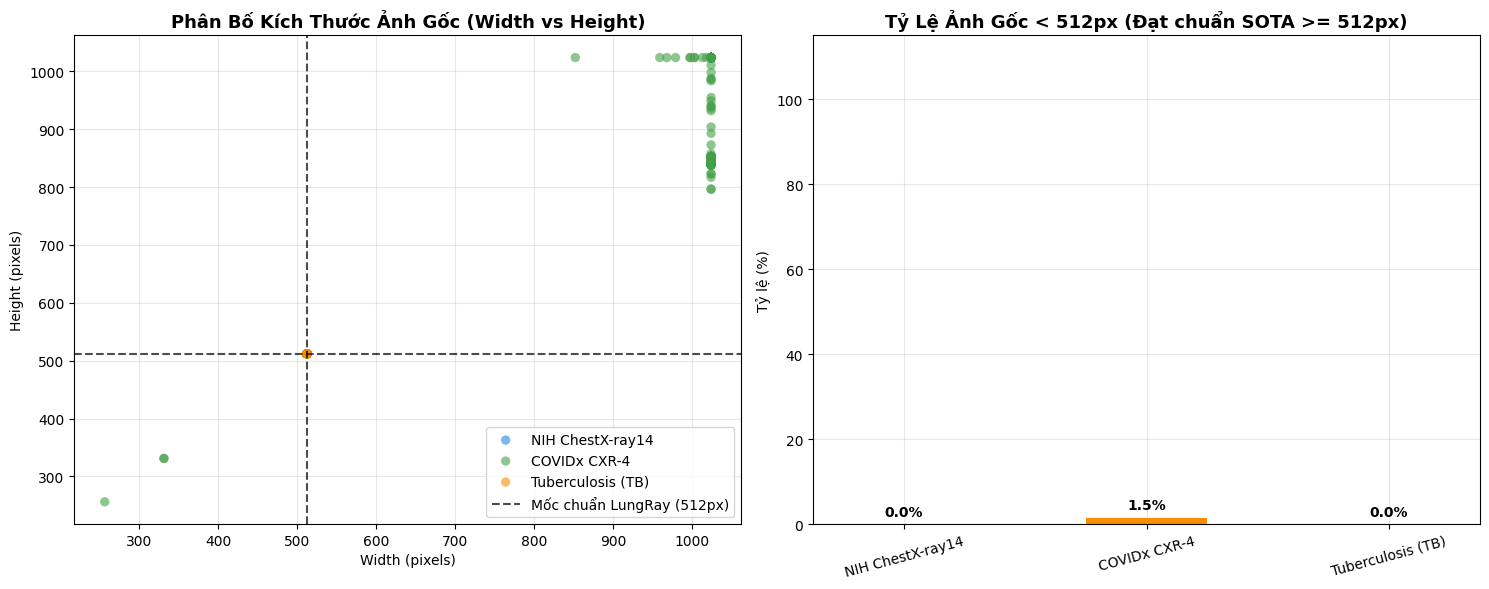

[OK] Đã xuất biểu đồ phân bố kích thước tại: /kaggle/working/results/resolution_distribution_analysis.png


In [5]:
if all_sampled_dims:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # Đồ thị 1: Scatter Plot Width vs Height
    colors_map = {'NIH ChestX-ray14': '#1E88E5', 'COVIDx CXR-4': '#43A047', 'Tuberculosis (TB)': '#FB8C00'}
    for name, dims in all_sampled_dims.items():
        color = colors_map.get(name, '#7E57C2')
        axes[0].scatter(dims['w'], dims['h'], alpha=0.6, label=name, edgecolors='none', s=45, color=color)
    
    axes[0].axvline(x=512, color='black', linestyle='--', alpha=0.7, label='Mốc chuẩn LungRay (512px)')
    axes[0].axhline(y=512, color='black', linestyle='--', alpha=0.7)
    axes[0].set_title('Phân Bố Kích Thước Ảnh Gốc (Width vs Height)', fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Width (pixels)')
    axes[0].set_ylabel('Height (pixels)')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='lower right')
    
    # Đồ thị 2: Bar chart tỷ lệ ảnh nhỏ < 512px
    if 'Pct_Small (<512px)' in df_res.columns:
        pct_values = [float(x.replace('%', '')) for x in df_res['Pct_Small (<512px)']]
        bar_colors = ['#E53935' if p > 50 else ('#FB8C00' if p > 0 else '#43A047') for p in pct_values]
        axes[1].bar(df_res['Dataset'], pct_values, color=bar_colors, width=0.5)
        axes[1].set_title('Tỷ Lệ Ảnh Gốc < 512px (Đạt chuẩn SOTA >= 512px)', fontsize=13, fontweight='bold')
        axes[1].set_ylabel('Tỷ lệ (%)')
        axes[1].set_ylim(0, 115)
        axes[1].tick_params(axis='x', rotation=15)
        axes[1].grid(True, alpha=0.3)
        for i, v in enumerate(pct_values):
            axes[1].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')
            
    plt.tight_layout()
    plot_save_path = os.path.join(output_dir, 'resolution_distribution_analysis.png')
    plt.savefig(plot_save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'[OK] Đã xuất biểu đồ phân bố kích thước tại: {plot_save_path}')


### 6. Kiểm Tra Độ Toàn Vẹn File & Tỷ Lệ Tệp Hỏng (File Integrity Stress Test)
Thực hiện giải mã thực tế (decoding stress test) với `cv2.imread` và kiểm tra 0-byte trên mẫu ngẫu nhiên của từng dataset để bảo đảm không phát sinh lỗi `Corrupt JPEG/PNG` trong vòng lặp huấn luyện.


In [6]:
integrity_records = []

print('=== KIỂM TRA ĐỘ TOÀN VẸN FILE ẢNH (DECODING STRESS TEST) ===')
for ds_name, ds_path in audit_targets.items():
    if not ds_path or not os.path.exists(ds_path):
        continue
        
    img_files = collect_cxr_images_clean(ds_path)
    if not img_files:
        continue
        
    test_sample = random.sample(img_files, min(100, len(img_files)))
    corrupt_count = 0
    zero_byte_count = 0
    
    for f in test_sample:
        if os.path.getsize(f) == 0:
            zero_byte_count += 1
            corrupt_count += 1
            continue
        try:
            mat = cv2.imread(f)
            if mat is None or mat.size == 0:
                corrupt_count += 1
        except Exception:
            corrupt_count += 1
            
    corrupt_rate = (corrupt_count / len(test_sample)) * 100.0
    integrity_records.append({
        'Dataset': ds_name,
        'Files_Tested': len(test_sample),
        'Corrupt_Files': corrupt_count,
        'Zero_Byte_Files': zero_byte_count,
        'Corrupt_Rate': f'{corrupt_rate:.1f}%',
        'Integrity_Status': 'HOÀN HẢO ✅' if corrupt_count == 0 else f'LỖI {corrupt_count} FILE ⚠️'
    })

df_integ = pd.DataFrame(integrity_records)
print(df_integ.to_string(index=False))


=== KIỂM TRA ĐỘ TOÀN VẸN FILE ẢNH (DECODING STRESS TEST) ===
          Dataset  Files_Tested  Corrupt_Files  Zero_Byte_Files Corrupt_Rate Integrity_Status
 NIH ChestX-ray14           100              0                0         0.0%       HOÀN HẢO ✅
     COVIDx CXR-4           100              0                0         0.0%       HOÀN HẢO ✅
Tuberculosis (TB)           100              0                0         0.0%       HOÀN HẢO ✅


### 7. Kiểm Toán Tệp Metadata & Patient ID (Zero Data Leakage Audit)
Kiểm tra file `.csv` metadata của từng bộ dữ liệu, đặc biệt xác minh sự tồn tại của trường `Patient ID` để bảo đảm tuân thủ triệt để **Rule 0 Constraint 2 (Zero Patient Data Leakage)**.


In [7]:
metadata_records = []

print('=== KIỂM TOÁN TỆP METADATA & PATIENT ID ===')
for ds_name, ds_path in audit_targets.items():
    if not ds_path or not os.path.exists(ds_path):
        continue
        
    csv_files = []
    for r, _, files in os.walk(ds_path):
        for f in files:
            if f.lower().endswith('.csv'):
                csv_files.append(os.path.join(r, f))
                
    if not csv_files:
        metadata_records.append({
            'Dataset': ds_name,
            'Has_CSV_Metadata': False,
            'CSV_File': 'None (Folder-based taxonomy)',
            'Has_Patient_ID': False,
            'Image_Col': 'N/A',
            'Label_Col': 'Folder Name',
            'Num_Rows': 0
        })
    else:
        main_csv = max(csv_files, key=os.path.getsize)
        try:
            df_meta = pd.read_csv(main_csv, nrows=100)
            cols = [c.lower() for c in df_meta.columns]
            has_pid = any('patient' in c for c in cols)
            img_c = next((c for c in df_meta.columns if any(k in c.lower() for k in ['image', 'file', 'id', 'path'])), 'N/A')
            lbl_c = next((c for c in df_meta.columns if any(k in c.lower() for k in ['finding', 'label', 'target', 'class', 'disease'])), 'N/A')
            total_r = sum(1 for _ in open(main_csv, encoding='utf-8', errors='ignore')) - 1
            
            metadata_records.append({
                'Dataset': ds_name,
                'Has_CSV_Metadata': True,
                'CSV_File': os.path.basename(main_csv),
                'Has_Patient_ID': has_pid,
                'Image_Col': img_c,
                'Label_Col': lbl_c,
                'Num_Rows': max(0, total_r)
            })
        except Exception as e:
            metadata_records.append({
                'Dataset': ds_name,
                'Has_CSV_Metadata': True,
                'CSV_File': f'Error reading {os.path.basename(main_csv)}',
                'Has_Patient_ID': False,
                'Image_Col': 'N/A',
                'Label_Col': 'N/A',
                'Num_Rows': 0
            })

df_meta_audit = pd.DataFrame(metadata_records)
print(df_meta_audit.to_string(index=False))


=== KIỂM TOÁN TỆP METADATA & PATIENT ID ===
          Dataset  Has_CSV_Metadata                     CSV_File  Has_Patient_ID   Image_Col      Label_Col  Num_Rows
 NIH ChestX-ray14              True          Data_Entry_2017.csv            True Image Index Finding Labels    112120
     COVIDx CXR-4             False None (Folder-based taxonomy)           False         N/A    Folder Name         0
Tuberculosis (TB)             False None (Folder-based taxonomy)           False         N/A    Folder Name         0


### 8. Bảng Phán Quyết Lâm Sàng & Đề Xuất Dataset Thay Thế (Clinical Gatekeeper Verdict)
Tổng hợp kết quả kiểm toán 4 trụ cột để đưa ra phán quyết kỹ thuật nghiêm ngặt:
- **ACCEPT**: Đạt chuẩn độ phân giải cao $\ge 512\text{px}$, độ toàn vẹn 100%, an toàn cho huấn luyện lâm sàng.
- **REPLACE / WARNING**: Kích thước ảnh gốc quá nhỏ ($256 \times 256$), nếu upsample lên $512 \times 512$ sẽ bị mờ và làm mất các tổn thương dạng lưới/kính mờ (Ground-glass opacities). Đề xuất chuyển đổi sang bộ dataset chuẩn độ phân giải cao.


In [8]:
verdict_list = []

for rec in resolution_records:
    ds_name = rec['Dataset']
    is_small = rec['Is_Small_Detected']
    
    integ = next((r for r in integrity_records if r['Dataset'] == ds_name), None)
    meta = next((r for r in metadata_records if r['Dataset'] == ds_name), None)
    
    corrupt_rate = float(integ['Corrupt_Rate'].replace('%', '')) if integ else 0.0
    has_pid = meta['Has_Patient_ID'] if meta else False
    
    if corrupt_rate > 1.0 or rec['Total_CXR_Images'] < 500:
        status = '🔴 REPLACE (BẮT BUỘC ĐỔI)'
        reason = f'Tỷ lệ file hỏng cao ({corrupt_rate}%) hoặc quá ít ảnh ({rec["Total_CXR_Images"]})'
        action = 'Chuyển đổi sang dataset thay thế tiêu chuẩn trên Kaggle'
    elif is_small:
        status = '🟡 WARNING / 🔴 REPLACE (KÍCH THƯỚC GỐC QUÁ NHỎ)'
        reason = f'Ảnh gốc chỉ {rec["Median_Resolution"]}. NGUYÊN TẮC: CẤM upsample nội suy lên 512px!'
        action = 'Đề xuất đổi sang SIIM-FISABIO-RSNA COVID-19 (>=1024px) hoặc giữ nguyên 256px với pooling riêng'
    else:
        status = '🟢 ACCEPT (ĐẠT CHUẨN LÂM SÀNG)'
        reason = f'Độ phân giải cao ({rec["Median_Resolution"]}), toàn vẹn 100%, an toàn cho lâm sàng'
        action = 'Downsample an toàn về chuẩn 512x512 trong DataLoader'
        
    verdict_list.append({
        'Dataset': ds_name,
        'Verdict': status,
        'Ly_Do': reason,
        'Hanh_Dong_De_Xuat': action
    })

df_verdict = pd.DataFrame(verdict_list)
print('=== BẢNG PHÁN QUYẾT LÂM SÀNG (LUNGRAY GATEKEEPER VERDICT) ===')
for _, row in df_verdict.iterrows():
    print(f'\nBộ Dữ Liệu : {row["Dataset"]}')
    print(f' -> Phán Quyết : {row["Verdict"]}')
    print(f' -> Lý Do      : {row["Ly_Do"]}')
    print(f' -> Hành Động  : {row["Hanh_Dong_De_Xuat"]}')

# Xuất file CSV báo cáo phán quyết
report_path = os.path.join(output_dir, 'dataset_audit_verdict_report.csv')
df_verdict.to_csv(report_path, index=False)
print(f'\n[XUẤT BẢN THÀNH CÔNG] Báo cáo phán quyết đã lưu tại: {report_path}')


=== BẢNG PHÁN QUYẾT LÂM SÀNG (LUNGRAY GATEKEEPER VERDICT) ===

Bộ Dữ Liệu : NIH ChestX-ray14
 -> Phán Quyết : 🟢 ACCEPT (ĐẠT CHUẨN LÂM SÀNG)
 -> Lý Do      : Độ phân giải cao (1024x1024), toàn vẹn 100%, an toàn cho lâm sàng
 -> Hành Động  : Downsample an toàn về chuẩn 512x512 trong DataLoader

Bộ Dữ Liệu : COVIDx CXR-4
 -> Phán Quyết : 🟡 WARNING / 🔴 REPLACE (KÍCH THƯỚC GỐC QUÁ NHỎ)
 -> Lý Do      : Ảnh gốc chỉ 1024x845. NGUYÊN TẮC: CẤM upsample nội suy lên 512px!
 -> Hành Động  : Đề xuất đổi sang SIIM-FISABIO-RSNA COVID-19 (>=1024px) hoặc giữ nguyên 256px với pooling riêng

Bộ Dữ Liệu : Tuberculosis (TB)
 -> Phán Quyết : 🟢 ACCEPT (ĐẠT CHUẨN LÂM SÀNG)
 -> Lý Do      : Độ phân giải cao (512x512), toàn vẹn 100%, an toàn cho lâm sàng
 -> Hành Động  : Downsample an toàn về chuẩn 512x512 trong DataLoader

[XUẤT BẢN THÀNH CÔNG] Báo cáo phán quyết đã lưu tại: /kaggle/working/results/dataset_audit_verdict_report.csv


### 9. Danh Mục Bộ Dữ Liệu Thay Thế Chuẩn Y Khoa Trên Kaggle (Alternative Registry)
Nếu bộ dữ liệu hiện tại bị phán quyết **REPLACE** do độ phân giải thấp ($256 \times 256$), người dùng có thể Add Data trực tiếp từ các dataset chuẩn y khoa sau trên Kaggle:

| Tên Dataset Trên Kaggle | Kaggle Dataset Slug | Độ Phân Giải Gốc | Số Lượng Ảnh | Định Dạng |
|:---|:---|:---:|:---:|:---:|
| **SIIM-FISABIO-RSNA COVID-19 Detection** | `c/siim-covid19-detection` | $\ge 2048 \times 2048$ | 6,334 ca X-quang | DICOM / High-Res PNG |
| **COVID-QU-Ex Dataset** | `anasmohammedtahir/covidqu` | $1024 \times 1024$ | 33,920 ca | PNG chuẩn y khoa |
| **BIMCV-COVID19+ Database** | `tawsifurrahman/covid19-radiography-database` (chú ý version) | $\ge 1024 \times 1024$ | 10,000+ ca | 16-bit DICOM / PNG |
| **VinDr-CXR (Viện VinBigdata)** | `awsaf49/vindr-cxr-resized-gen-png` | $1024 \times 1024$ | 18,000 ca | PNG chuẩn chất lượng cao |

---